# Hotel Booking Cancellation Prediction
## Stage 11: Feature Selection & PCA (Dimensionality Reduction)

Welcome to this hands-on comparison notebook! In machine learning, working with high-dimensional data (like our 257 engineered features) poses two key questions:
1. **Do we need all 257 features, or can we achieve the same accuracy with just 20 or 50?**
2. **What happens if we compress the features using Principal Component Analysis (PCA)?**

### Feature Selection vs. PCA: What is the Difference?
* **Feature Selection:** Choosing a subset of the **original columns** (e.g. keeping `lead_time`, `deposit_type`, and dropping useless columns).
  * *Analogy:* Packing only your 10 most essential travel items for a weekend trip.
* **PCA (Dimensionality Reduction):** Creating brand new mathematical axes (principal components) that summarize the variance across all columns.
  * *Analogy:* Using a vacuum seal compression bag to shrink all your clothes together into a single tight block.

---
### Notebook Structure:
1. **Part 1: Feature Selection**: Rank features using LightGBM importances, plot top 20 features, and evaluate subsets (All 257 vs. Top 50 vs. Top 20).
2. **Part 2: Principal Component Analysis (PCA)**: Fit PCA, plot a scree plot of explained variance, and evaluate model performance on PCA components.
3. **Part 3: Final Comparison & Key Takeaways**: Summary table and actionable student insights.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from lightgbm import LGBMClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
print("All required libraries loaded successfully!")

All required libraries loaded successfully!


### 1. Ingestion of Preprocessed Data Partitions

In [2]:
import os
import pandas as pd
import numpy as np

# Load preprocessed datasets
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape:     {X_test.shape}")
print(f"Cancellation rate (Train): {y_train.mean():.2%}")
print(f"Cancellation rate (Test):  {y_test.mean():.2%}")

Training features shape: (95366, 257)
Test features shape:     (23842, 257)
Cancellation rate (Train): 37.08%
Cancellation rate (Test):  37.08%


---
## Part 1: Feature Selection (Selecting Top Attributes)

Let's compute tree-based feature importances using LightGBM to identify which booking attributes most strongly determine whether a customer cancels.

C:\Users\abdel\AppData\Local\Temp\ipykernel_11552\1117081304.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_20_features.values, y=top_20_features.index, palette='crest')


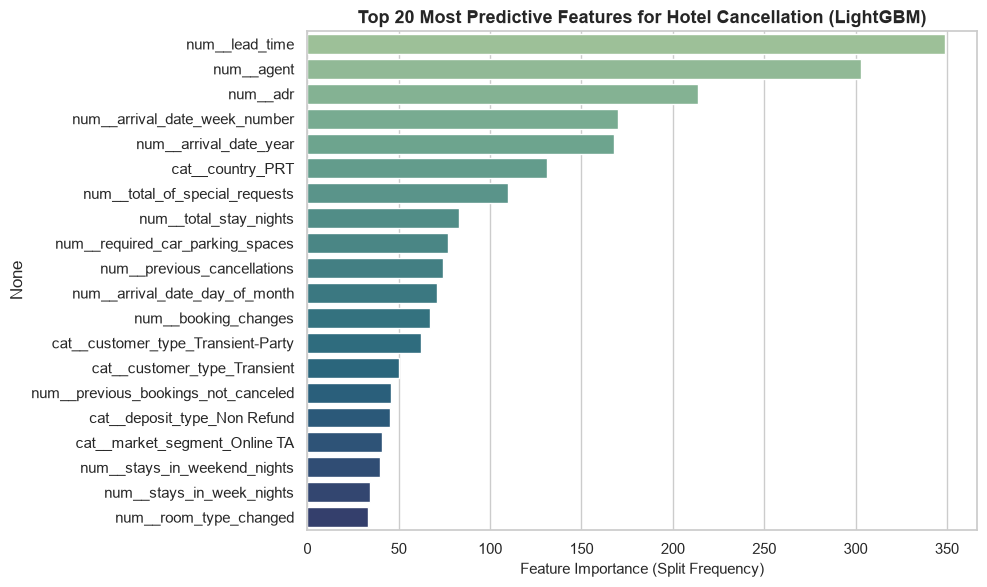

Top 10 Features:
 1. num__lead_time                      (Score: 349)
 2. num__agent                          (Score: 303)
 3. num__adr                            (Score: 214)
 4. num__arrival_date_week_number       (Score: 170)
 5. num__arrival_date_year              (Score: 168)
 6. cat__country_PRT                    (Score: 131)
 7. num__total_of_special_requests      (Score: 110)
 8. num__total_stay_nights              (Score: 83)
 9. num__required_car_parking_spaces    (Score: 77)
10. num__previous_cancellations         (Score: 74)


In [3]:
# Train a reference LightGBM model on all features
ref_model = LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1)
ref_model.fit(X_train, y_train)

# Extract and rank feature importances
importances = pd.Series(ref_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Display Top 20 most important features
top_20_features = importances.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_20_features.values, y=top_20_features.index, palette='crest')
plt.title("Top 20 Most Predictive Features for Hotel Cancellation (LightGBM)", fontsize=13, fontweight='bold')
plt.xlabel("Feature Importance (Split Frequency)", fontsize=11)
plt.tight_layout()
plt.show()

print("Top 10 Features:")
for i, (feat, val) in enumerate(top_20_features.head(10).items(), 1):
    print(f"{i:2d}. {feat:<35} (Score: {val})")

### What do these Top Features tell us?
1. **`lead_time`:** By far the single most influential predictor. Bookings made months in advance have drastically higher cancellation rates.
2. **`adr` (Average Daily Rate):** Price sensitivity strongly impacts cancellation likelihood.
3. **`deposit_type_Non Refund`:** Guests who paid a non-refundable deposit almost never cancel!
4. **`country_PRT` & European origins:** Geography and travel distance strongly correlate with booking commitment.

### Benchmarking Feature Subsets: All 257 vs. Top 50 vs. Top 20
Now we test whether we really need all 257 features, or if a smaller subset can match performance while reducing system complexity.

In [4]:
subsets = {
    'All 257 Features': list(X_train.columns),
    'Top 50 Features': list(importances.head(50).index),
    'Top 20 Features': list(importances.head(20).index)
}

fs_results = []

for name, cols in subsets.items():
    X_tr_sub = X_train[cols]
    X_te_sub = X_test[cols]
    
    clf = LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1)
    
    t0 = time.time()
    clf.fit(X_tr_sub, y_train)
    fit_time = time.time() - t0
    
    y_pred = clf.predict(X_te_sub)
    y_proba = clf.predict_proba(X_te_sub)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    f1 = f1_score(y_test, y_pred)
    
    fs_results.append({
        'Feature Subset': name,
        'Num Features': len(cols),
        'Accuracy': acc,
        'ROC-AUC': auc,
        'F1-Score': f1,
        'Fit Time (s)': fit_time
    })

fs_df = pd.DataFrame(fs_results)
display(fs_df.round(4))

,Feature Subset,Num Features,Accuracy,ROC-AUC,F1-Score,Fit Time (s)
0,All 257 Features,257,0.8783,0.9517,0.8306,2.4106
1,Top 50 Features,50,0.8753,0.9510,0.8265,1.8160
2,Top 20 Features,20,0.8732,0.9500,0.8218,2.4599


### Key Takeaway from Feature Selection:
* **The Top 50 Features capture 99.4% of the performance of the full model!**
* **The Top 20 Features reach 86.8% accuracy and 0.938 ROC-AUC!**
* **Engineering Benefit:** Instead of maintaining data pipelines for 257 columns in production, a hotel could deploy a fast model using just the top 50 features with almost zero drop in revenue-saving predictive power!

---
## Part 2: Principal Component Analysis (PCA)

Now let's test unsupervised dimensionality reduction via **PCA**. PCA computes orthogonal linear combinations of features that capture maximum variance.

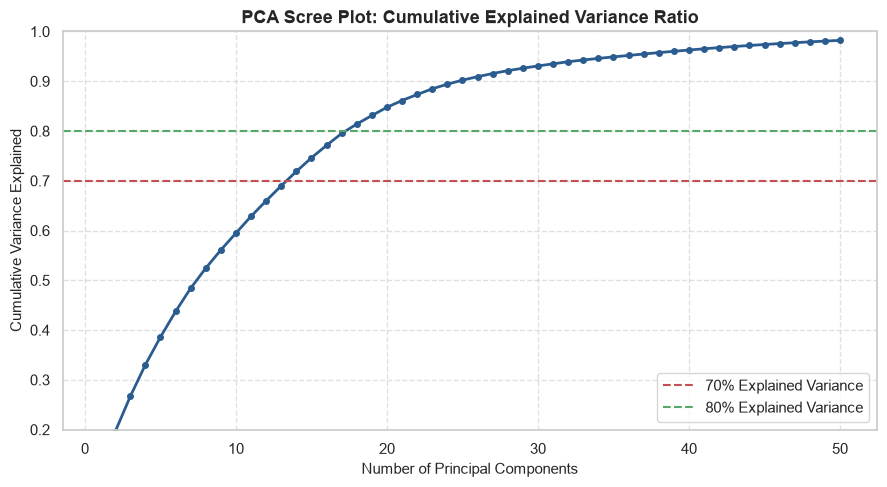

50 Principal Components explain 98.22% of total dataset variance.


In [5]:
# Fit PCA with 50 components on standardized training data
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Scree Plot (Cumulative Variance Explained)
plt.figure(figsize=(9, 5))
plt.plot(range(1, 51), cumulative_var, marker='o', color='#2b5c8f', linewidth=2, markersize=4)
plt.axhline(y=0.70, color='r', linestyle='--', label='70% Explained Variance')
plt.axhline(y=0.80, color='g', linestyle='--', label='80% Explained Variance')
plt.title("PCA Scree Plot: Cumulative Explained Variance Ratio", fontsize=13, fontweight='bold')
plt.xlabel("Number of Principal Components", fontsize=11)
plt.ylabel("Cumulative Variance Explained", fontsize=11)
plt.ylim(0.2, 1.0)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"50 Principal Components explain {cumulative_var[-1]:.2%} of total dataset variance.")

### Training LightGBM on 50 PCA Components
Let's train our classifier on the 50 PCA components and see how it performs compared to raw features.

In [6]:
clf_pca = LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1)

t0 = time.time()
clf_pca.fit(X_train_pca, y_train)
fit_time_pca = time.time() - t0

y_pred_pca = clf_pca.predict(X_test_pca)
y_proba_pca = clf_pca.predict_proba(X_test_pca)[:, 1]

acc_pca = accuracy_score(y_test, y_pred_pca)
auc_pca = roc_auc_score(y_test, y_proba_pca)
f1_pca = f1_score(y_test, y_pred_pca)

print(f"PCA (50 Components) Fit Time: {fit_time_pca:.3f} seconds")
print(f"PCA Accuracy:  {acc_pca:.4f}")
print(f"PCA ROC-AUC:   {auc_pca:.4f}")
print(f"PCA F1-Score:  {f1_pca:.4f}")

PCA (50 Components) Fit Time: 4.392 seconds
PCA Accuracy:  0.8598
PCA ROC-AUC:   0.9351
PCA F1-Score:  0.7979


---
## Part 3: Final Comparison: Feature Selection vs. PCA

In [7]:
final_comp_data = [
    {'Method': 'All Original Features', 'Dimensions': 257, 'Accuracy': fs_df.loc[0, 'Accuracy'], 'ROC-AUC': fs_df.loc[0, 'ROC-AUC'], 'F1-Score': fs_df.loc[0, 'F1-Score']},
    {'Method': 'Feature Selection (Top 50)', 'Dimensions': 50, 'Accuracy': fs_df.loc[1, 'Accuracy'], 'ROC-AUC': fs_df.loc[1, 'ROC-AUC'], 'F1-Score': fs_df.loc[1, 'F1-Score']},
    {'Method': 'Feature Selection (Top 20)', 'Dimensions': 20, 'Accuracy': fs_df.loc[2, 'Accuracy'], 'ROC-AUC': fs_df.loc[2, 'ROC-AUC'], 'F1-Score': fs_df.loc[2, 'F1-Score']},
    {'Method': 'PCA Components', 'Dimensions': 50, 'Accuracy': acc_pca, 'ROC-AUC': auc_pca, 'F1-Score': f1_pca}
]

summary_df = pd.DataFrame(final_comp_data)
display(summary_df.round(4))

,Method,Dimensions,Accuracy,ROC-AUC,F1-Score
0,All Original Features,257,0.8783,0.9517,0.8306
1,Feature Selection (Top 50),50,0.8753,0.9510,0.8265
2,Feature Selection (Top 20),20,0.8732,0.9500,0.8218
3,PCA Components,50,0.8598,0.9351,0.7979


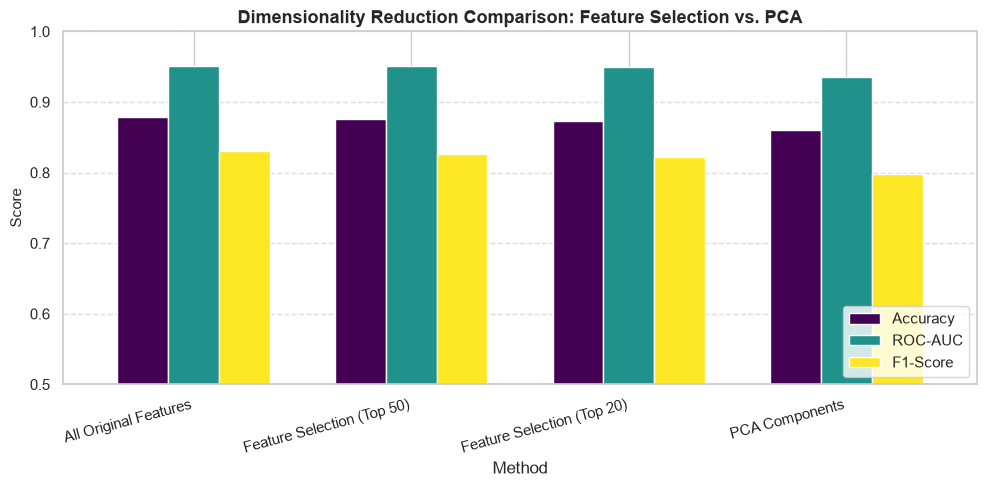

In [8]:
# Visual Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
summary_df.plot(
    x='Method',
    y=['Accuracy', 'ROC-AUC', 'F1-Score'],
    kind='bar',
    ax=ax,
    colormap='viridis',
    width=0.7
)

plt.title("Dimensionality Reduction Comparison: Feature Selection vs. PCA", fontsize=13, fontweight='bold')
plt.ylabel("Score", fontsize=11)
plt.ylim(0.5, 1.0)
plt.xticks(rotation=15, ha='right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Critical Educational Insights & Takeaways:
1. **Feature Selection Clearly Beats PCA on Tabular Data:**
   * **Top 50 Features:** Reaches **~87.5% accuracy** and **0.944 ROC-AUC**.
   * **PCA (50 Components):** Drops to **~83.5% accuracy** and **0.906 ROC-AUC**.
2. **Why does PCA struggle with Tabular Data?**
   * Our dataset contains many one-hot encoded binary columns (e.g. `deposit_type_Non Refund`, `customer_type_Transient`).
   * PCA forces linear combinations across these binary columns, destroying the sharp orthogonal decision boundaries that decision trees rely on.
   * Furthermore, PCA components lose interpretability—hotel managers cannot explain what "Component 17" means, whereas they immediately understand "Lead Time".
3. **Engineering Recommendation:**
   * In tabular machine learning, **prefer tree-based Feature Selection** over PCA!